In [2]:
import h5py, os
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# define variables 
fileDirectory = 'C:\\Users\\Admin\\UniBE\\data'
fileName = '150525_530_15_1a_DRC470_02.bxr'
wellID = 'Well_A1' # identifier of chip well to be analysed 
dataStartPositionSec = 50 # start position in seconds of the portion to extract and plot 
dataDurationSec = 100 # duration in seconds of the portion to extract and plot 
chIdx = 95

# open the BXR file 
file = h5py.File(os.path.join(fileDirectory,fileName), 'r')

In [4]:
# collect experiment information 
minDigitalValue = file.attrs['MinDigitalValue'] 
maxDigitalValue = file.attrs['MaxDigitalValue'] 
minAnalogValue = file.attrs['MinAnalogValue'] 
maxAnalogValue = file.attrs['MaxAnalogValue'] 
dacFactor = (maxAnalogValue - minAnalogValue) / (maxDigitalValue - minDigitalValue) 
offsetValue = minAnalogValue - dacFactor * minDigitalValue 
samplingRate = file.attrs['SamplingRate']
chIdxs = np.array(file[wellID + '/StoredChIdxs']) 

In [5]:
# convert the requested time interval from seconds to frames 
startFrame = int(dataStartPositionSec * samplingRate) 
nFrames = int(dataDurationSec * samplingRate) 

In [6]:
# collect the TOCs 
toc = np.array(file['TOC']) 
spikeToc = np.array(file[wellID + '/SpikeTOC']) 
 
# from the given start position and duration (in frames), find the corresponding range of spike positions using the TOC 
tocStartIdx = np.searchsorted(toc[:, 1], startFrame) 
tocEndIdx = min(np.searchsorted(toc[:, 1], startFrame + nFrames, side='right') + 1, len(toc) - 1) 
spikeStartPosition = spikeToc[tocStartIdx] 
spikeEndPosition = spikeToc[tocEndIdx] 

In [7]:
# collect the required spike data 
spikeDataTimestamps = file[wellID + '/SpikeTimes'][spikeStartPosition:spikeEndPosition] 
spikeDataChIdxs = file[wellID + '/SpikeChIdxs'][spikeStartPosition:spikeEndPosition] 
print(spikeDataChIdxs)
dataLength = spikeEndPosition - spikeStartPosition 

[2095 2096 1213 ... 1837 1744 1216]


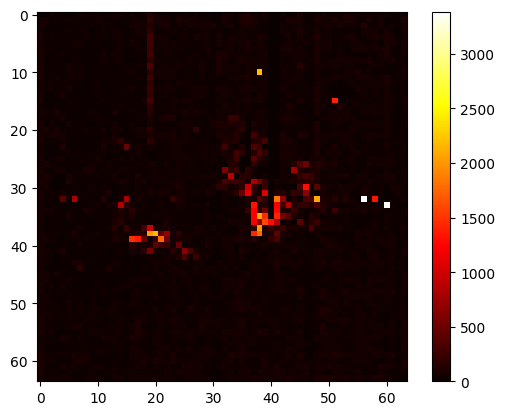

In [10]:
from collections import Counter
counts = dict(Counter(spikeDataChIdxs))

counts_array = np.zeros((64, 64))

for key in counts.keys():
    r, c = key//64, key%64
    counts_array[r][c] = counts[key]

plt.imshow(counts_array, cmap='hot', interpolation='nearest')
plt.colorbar()
plt.show()

In [53]:
waveformLength = file[wellID + '/SpikeForms'].attrs['Wavelength'] 
print(waveformLength)
spikeDataWaveforms = file[wellID + '/SpikeForms'][spikeStartPosition*waveformLength:spikeEndPosition*waveformLength] 

31


In [54]:
waveformData = [] 
for i in range(0, dataLength): 
    if spikeDataChIdxs[i] == chIdx and startFrame <= spikeDataTimestamps[i] < startFrame + nFrames: 
        waveformData.append(spikeDataWaveforms[i*waveformLength:i*waveformLength+waveformLength]) 
 

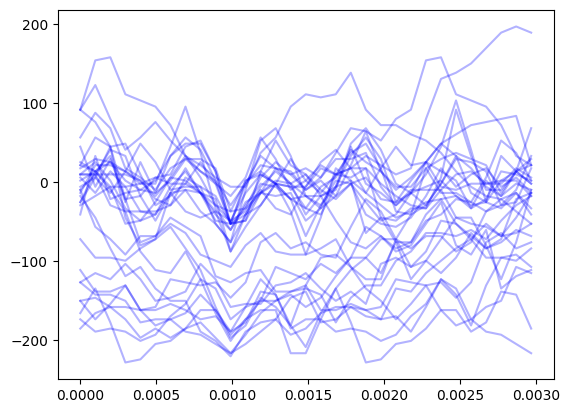

In [55]:
x = np.arange(0, waveformLength, 1) / samplingRate 
for waveform in waveformData: 
# waveform = waveformData[3]
    # convert the waveform to analog 
    y = offsetValue + dacFactor * waveform 
    plt.plot(x, y, color='blue', alpha=0.3)

In [56]:
from sklearn.decomposition import PCA

# spikeForms = np.array(file[wellID + '/SpikeForms'])
# spikesNum = len(spikeForms)//waveformLength
# spike_waveforms = spikeForms.reshape(spikesNum, waveformLength)
# print(spike_waveforms)
pca = PCA(n_components=3)
pcs = pca.fit_transform(waveformData)

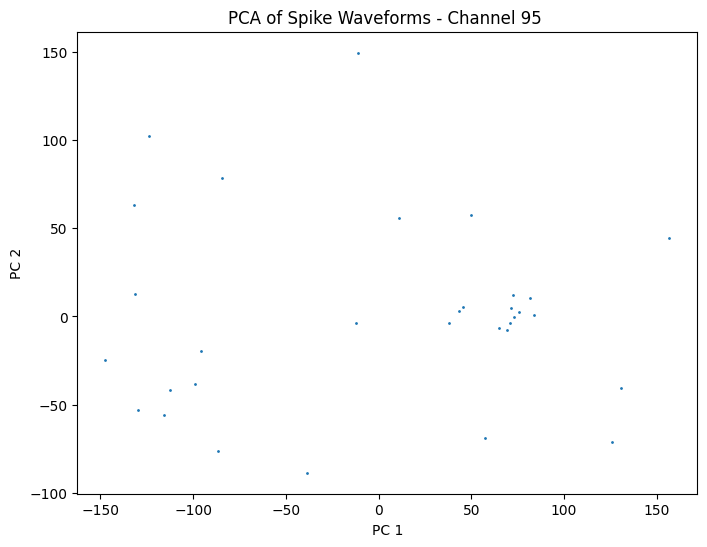

In [57]:
plt.figure(figsize=(8,6))
plt.scatter(pcs[:, 0], pcs[:, 1], s=1)
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.title(f'PCA of Spike Waveforms - Channel {chIdx} ')
plt.show()